In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_curve, auc, roc_auc_score

# Data Preparation

In [4]:
df = pd.read_csv('./data/data-week-3.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

# Validation Framework

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

# Encode & Train

In [6]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

In [7]:
y_train

array([0, 0, 1, ..., 1, 0, 1], shape=(4225,))

In [8]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression()
model.fit(X_train, y_train)

/home/rwin/Documents/github/ml-forge/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [9]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.801277501774308)

## Accuracy

$$
\mathbf{Accuracy} = \frac{\#\text{Correct predictions}}{\#\text{Total predictions}}
$$

In [10]:
acc = (y_val == churn_decision).sum() / len(y_val)
print(f"{(y_val == churn_decision).sum()} / {len(y_val)} = {acc}")

1129 / 1409 = 0.801277501774308


In [11]:
(y_val == churn_decision).mean()

np.float64(0.801277501774308)

In [12]:
accuracy_score(y_val, y_pred >= 0.5)

0.801277501774308

In [13]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print("Threshold: %.2f, Accuracy:%.3f" % (t, score))
    scores.append(score)

Threshold: 0.00, Accuracy:0.274
Threshold: 0.05, Accuracy:0.509
Threshold: 0.10, Accuracy:0.598
Threshold: 0.15, Accuracy:0.664
Threshold: 0.20, Accuracy:0.707
Threshold: 0.25, Accuracy:0.737
Threshold: 0.30, Accuracy:0.759
Threshold: 0.35, Accuracy:0.766
Threshold: 0.40, Accuracy:0.780
Threshold: 0.45, Accuracy:0.793
Threshold: 0.50, Accuracy:0.801
Threshold: 0.55, Accuracy:0.798
Threshold: 0.60, Accuracy:0.797
Threshold: 0.65, Accuracy:0.784
Threshold: 0.70, Accuracy:0.765
Threshold: 0.75, Accuracy:0.744
Threshold: 0.80, Accuracy:0.730
Threshold: 0.85, Accuracy:0.726
Threshold: 0.90, Accuracy:0.726
Threshold: 0.95, Accuracy:0.726
Threshold: 1.00, Accuracy:0.726


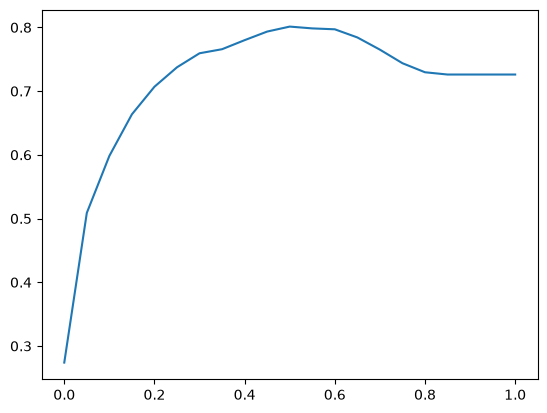

In [14]:
plt.plot(thresholds, scores)

### dummy model

$\text{Threshold} = 1.0 \rightarrow$ every customer is predicted as "no churn"

In [15]:
from collections import Counter

Counter(y_pred >= 1.0) 

Counter({np.False_: 1409})

- No True class (nobody is churning)

In [16]:
1 - y_val.mean()

np.float64(0.7260468417317246)

In [17]:
accuracy_score(y_val, y_pred >= 1.0) # checkout the plot

0.7260468417317246

Assuming `1` means churn and `0` means no churn, `y_val` contains the actual outcomes for the validation customers.  
Because the labels are zeros and ones, `y_val.mean()` is the fraction of customers who actually churned—the churn rate.  
For example, if `y_val.mean()` is `0.2`, then 20% churned and the remaining 80% did not.  
The expression `y_pred >= 1.0` converts each prediction into a class prediction: `True` for churn and `False` for no churn.  
If every value in `y_pred` is below `1.0`, this expression predicts no churn for every customer.  
`accuracy_score(y_val, y_pred >= 1.0)` then measures the fraction of those predictions that match the actual outcomes.  
For an always-no-churn prediction, it is correct exactly for the customers who did not churn.  
Therefore, that model’s accuracy is `1 - y_val.mean()`; this is not automatically the accuracy of your trained model.  
- A model that predicts **churn for everyone** has accuracy `y_val.mean()`.  
- A model that predicts **no churn for everyone** has accuracy `1 - y_val.mean()`.

### class imbalance
- there are many more instances of one class than of the other.

In [18]:
Counter(y_val)

Counter({np.int64(0): 1023, np.int64(1): 386})

In [19]:
print(accuracy_score(y_val, y_pred >= 0.5)) # our model accuracy
print(accuracy_score(y_val, y_pred >= 1.0)) # dummy model accuracy

0.801277501774308
0.7260468417317246


-  We can see that the improvement of the original model with respect to the dummy model is not as high as we would expect.

In [20]:
print(y_val.mean()) # churn rate
print(1-y_val.mean()) # non-churners fraction

0.2739531582682754
0.7260468417317246


With such an imbalance, a model can get a high accuracy by always predicting **the majority class**, while being completely useless for the **minority class**

For a model that predicts **no churn for everyone**. It correctly labels every actual non-churner, so its **specificity** (the fraction of actual non-churners it correctly identifies) is 100%. But it labels every actual churner as a non-churner, so it finds **none** of the churners: its **recall for churn** is 0%. That makes it a useful baseline for comparison, but useless for the goal of identifying customers likely to churn. A high overall accuracy can hide this failure, especially when most customers do not churn.

## Confusion table
- Confusion table is a way of measuring different types of errors and correct decisions that binary classifiers can make.

For churn prediction, each customer in the validation set falls into one of four categories, depending on what we predicted and what actually happened:

| Prediction | Actual | Name |
|------------|--------|------|
| Customer will churn (positive) | Churned | True Positive (TP) |
| Customer will churn (positive) | Did not churn | False Positive (FP) |
| Customer will not churn (negative) | Churned | False Negative (FN) |
| Customer will not churn (negative) | Did not churn | True Negative (TN) |


$$
g(\mathbf{x}_i) \longrightarrow
\begin{cases}
\underbrace{
g(\mathbf{x}_i)>t \longrightarrow \text{Churn (Positive)}
}_{\text{Prediction}}
\longrightarrow
\begin{cases}
\underbrace{\text{Customer Churned}}_{\text{Actual}}
\longrightarrow \text{True Positive}
\\
\underbrace{\text{Customer didn't Churn}}_{\text{Actual}}
\longrightarrow \text{False Positive}
\end{cases}
\\[1.5em]
\underbrace{
g(\mathbf{x}_i)<t \longrightarrow \text{No Churn (Negative)}
}_{\text{Prediction}}
\longrightarrow
\begin{cases}
\underbrace{\text{Customer Churned}}_{\text{Actual}}
\longrightarrow \text{False Negative}
\\
\underbrace{\text{Customer didn't Churn}}_{\text{Actual}}
\longrightarrow \text{True Negative}
\end{cases}
\end{cases}
$$

In [21]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [22]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [23]:
tp, tn, fp, fn, tp+tn+fp+fn

(np.int64(214), np.int64(915), np.int64(108), np.int64(172), np.int64(1409))

$$
\begin{array}{c|c|c}
& g(\mathbf{x}_i)<t \; (\text{Predicted Negative})
& g(\mathbf{x}_i)>t \; (\text{Predicted Positive}) \\
\hline
y=0 \; (\text{Actual Negative})
& \underbrace{915}_{TN}
& \underbrace{108}_{FP}
\\[1em]
y=1 \; (\text{Actual Positive})
& \underbrace{172}_{FN}
& \underbrace{214}_{TP}
\end{array}
$$

In [24]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[915, 108],
       [172, 214]])


|                | Predicted negative | Predicted positive |
|----------------|--------------------|--------------------|
| Actual negative | TN = 915          | FP = 108           |
| Actual positive | FN = 172          | TP = 214           |

In [25]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.08],
       [0.12, 0.15]])

- So $65\%$ of all customers are **true negatives**, $8\%$ **false positives**, $12\%$ **false negatives** and $15\%$ **true positives**.
- Accuracy is the sum of the diagonal - the correct decisions TN and TP - divided by the total. 

In [26]:
(915+214)/1409

0.801277501774308

## Precision
- Precision tells us the fraction of positive predictions that are correct

$P = \frac{TP}{TP + FP}$

In [27]:
p = tp / (tp + fp)
p

np.float64(0.6645962732919255)

we send a retention email to everyone **predicted to churn**. That is 214 + 108 = 322 people, but only 214 of them (the true positives) were actually going to leave. The other 108 - about a third of all emails - go to customers who were never at risk, and the discount we send them is wasted.



## Recall
- Recall measures the fraction of actual positive instances that we identified correctly.

$ R = \frac{TP}{TP + FN}$

In [28]:
r = tp / (tp + fn)
r

np.float64(0.5544041450777202)

214 + 172 = 386 customers **actually churned**, but our model flagged only 214 of them. For the remaining 172 - about 45% of all churners - we did nothing: no email, no discount, and the customer left.

actual churners | Flagged
----------------|--------
Person1|$\checkmark$     
Person2|$\checkmark$
Person3|$\checkmark$
Person4| X

$\text{Recall} = \frac{3}{4} = 75\%$

- accuracy said 80% correct, only 4 points above the dummy model. 
- Of the customers we alert, two thirds are real (**precision 66%**).
- we miss almost half of the customers who leave (**recall 55%**).



## ROC 
- Receiver Operating Characteristic
- Precision and recall look at the model at one fixed threshold. A ROC curve looks at all possible thresholds at once.

### TPR
- The true positive rate is the fraction of **actual positives** we identified correctly - same as recall
- This is the metric we want to maximize.

$$TPR = \frac{TP}{TP + FN}$$

### FPR
- The false positive rate is the fraction of **actual negatives** we got wrong
- This is the metric we want to minimize.

$$FPR = \frac{FP}{FP + TN}$$

for threshold = 0.5:

In [29]:
tpr = tp / (tp + fn)
fpr = fp / (fp + tn)

In [30]:
tpr, fpr

(np.float64(0.5544041450777202), np.float64(0.10557184750733138))

we bother 10% of the customers who were never going to churn.

In [31]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (actual_positive & predict_positive).sum()
    tn = (actual_negative & predict_negative).sum()
    fp = (actual_negative & predict_positive).sum()
    fn = (actual_positive & predict_negative).sum()

    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

In [32]:
df_scores

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.00,386,1023,0,0,1.000000,1.000000
1,0.01,385,903,1,120,0.997409,0.882698
2,0.02,384,812,2,211,0.994819,0.793744
3,0.03,382,753,4,270,0.989637,0.736070
4,0.04,380,708,6,315,0.984456,0.692082
...,...,...,...,...,...,...,...
96,0.96,0,0,386,1023,0.000000,0.000000
97,0.97,0,0,386,1023,0.000000,0.000000
98,0.98,0,0,386,1023,0.000000,0.000000
99,0.99,0,0,386,1023,0.000000,0.000000


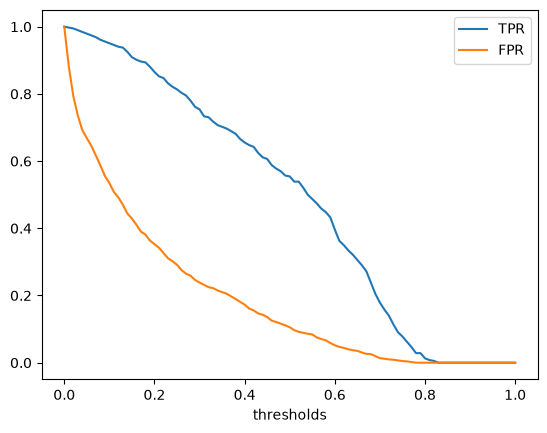

In [33]:
plt.plot(df_scores.threshold, df_scores.tpr, label='TPR')
plt.plot(df_scores.threshold, df_scores.fpr, label='FPR')
plt.xlabel("thresholds")
plt.legend()

- What the shape means:
  - When the threshold is very low, the model predicts “churn” for almost everyone.
  - That makes TPR very high, because it catches many actual churners.
  - But FPR also rises a lot, because it flags many non-churners too.
  - When the threshold is very high, the model predicts “churn” for almost nobody.
  - Then both TPR and FPR drop toward zero; you miss most churners, but you irritate very few customers.

- The important tradeoff:
  - There is no “free” good threshold.
  - **As the threshold grows, we flag fewer customers, so both the TPR and the FPR fall**
  - Lower threshold = better recall, worse precision / more wasted retention emails
  - Higher threshold = better precision, worse recall / more missed churners

- At the default threshold of 0.5, the actual confusion table is:
  - TN = 915
  - FP = 108
  - FN = 172
  - TP = 214

- From that:
  - Accuracy = (915 + 214) / 1409 = 0.805 = 80.5%
  - Precision = 214 / (214 + 108) = 0.665 = 66.5%
  - Recall = 214 / (214 + 172) = 0.554 = 55.4%
  - FPR = 108 / (108 + 915) = 0.106 = 10.6%

- So the plot is telling:
  - the model is not terrible, but it is not strong enough to confidently catch most churners without also flagging a bunch of non-churners
  - the real business decision is threshold tuning based on cost:
    - if churn is very expensive, lower the threshold and accept more false alarms
    - if sending too many unnecessary emails is expensive, keep the threshold higher and accept missing some churners

- practical interpretation:
  - The TPR and FPR curves are moving together as threshold changes, which indicates the model has some signal but not extremely clean separation
  - The gap between them is not huge, so the model is useful but not a “perfect classifier”


#### random model

In [34]:
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))

In [35]:
accuracy_score(y_val, y_rand >= 0.5)

0.5017743080198722

- A coin flip

In [36]:
def tpr_fpr_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (actual_positive & predict_positive).sum()
        tn = (actual_negative & predict_negative).sum()

        fp = (actual_negative & predict_positive).sum()
        fn = (actual_positive & predict_negative).sum()

        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores

In [37]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)

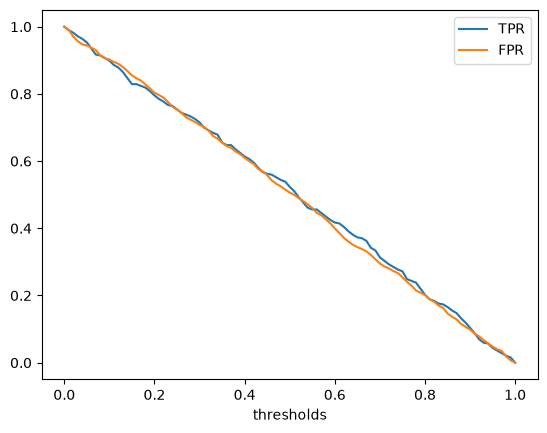

In [38]:
plt.plot(df_rand.threshold, df_rand.tpr, label='TPR')
plt.plot(df_rand.threshold, df_rand.fpr, label='FPR')
plt.xlabel("thresholds")
plt.legend()

- **The TPR and FPR lines almost overlap.** At a given threshold, the random model catches churners at roughly the same rate that it falsely flags non-churners.
- **Raising the threshold lowers both rates together.** The model predicts churn for fewer customers, but it doesn’t become better at distinguishing churners from non-churners.
- **At a low threshold**, both rates are near 1: almost everyone is flagged.
- **Around 0.5**, both are roughly 0.5: the random scores flag about half of each group.
- **At a high threshold**, both approach 0: almost nobody is flagged.
- The small wiggles and occasional gaps are expected from one finite random sample; they don’t indicate real predictive signal.

**Takeaway:** this is a useful baseline because it shows what random guessing looks like: the rates move together, with no consistent advantage in catching actual churners over generating false alarms. When you compare your model later, look for its TPR to be meaningfully higher than its FPR at the same threshold. This is a threshold plot, not an ROC plot.

**For the random model, at any threshold the fraction of positives we catch is the same as the fraction of negatives we bother - it cannot tell the two groups apart.**

### Ideal model

- every churner gets a higher score than every non-churner.
    - sort the customers so all 1023 negatives come first, then all 386 positives
    - give them scores evenly spread from `0 to 1`

In [39]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()

y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal_pred = np.linspace(0, 1, len(y_val))

Makes the model ideal by construction: 
- it puts all **1,023 non-churners first**, then all **386 churners**, and assigns scores that increase with that ordering. There are 1,409 validation examples total.

In [40]:
num_neg/(num_neg + num_pos)

np.float64(0.7260468417317246)

In [41]:
1 - y_val.mean()

np.float64(0.7260468417317246)

- We should put the threshold At the fraction of negatives, `0.726` - the ideal score that separates the two groups

In [42]:
accuracy_score(y_ideal, y_ideal_pred >= 0.726)

1.0

For this validation set, there are $1{,}023$ non-churners (label $0$) and $386$ churners (label $1$), for $1{,}409$ customers total. The ideal construction sorts the labels so that every $0$ comes before every $1$:

$$
\underbrace{0,\ldots,0}_{1{,}023\ \text{non-churners}},
\underbrace{1,\ldots,1}_{386\ \text{churners}}.
$$

Then it assigns scores evenly from $0$ to $1$. Using zero-based index $i$:

$$
s_i = \frac{i}{1{,}409 - 1} = \frac{i}{1{,}408},
\qquad i=0,\ldots,1{,}408.
$$

`np.linspace(0, 1, 1409)` assigns each of the $1{,}409$ elements an evenly spaced score from $0$ to $1$:


Thus, the scores are

$$
0,\ \frac{1}{1408},\ \frac{2}{1408},\ \ldots,\ \frac{1407}{1408},\ 1.
$$


while the first churner has index $1{,}023$ and score

$$
s_{1{,}023} = \frac{1{,}023}{1{,}408} \approx 0.72656.
$$

A threshold between these scores—for example, $0.726$—separates the two groups perfectly: scores below the threshold belong to non-churners, and scores at or above it belong to churners. This is an idealized ranking built from the true labels, not a model prediction.

In [43]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)
df_ideal[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,386,882,0,141,1.000000,0.862170
20,0.2,386,741,0,282,1.000000,0.724340
30,0.3,386,600,0,423,1.000000,0.586510
40,0.4,386,459,0,564,1.000000,0.448680
50,0.5,386,319,0,704,1.000000,0.311828
60,0.6,386,178,0,845,1.000000,0.173998
70,0.7,386,37,0,986,1.000000,0.036168
80,0.8,282,0,104,1023,0.730570,0.000000
90,0.9,141,0,245,1023,0.365285,0.000000


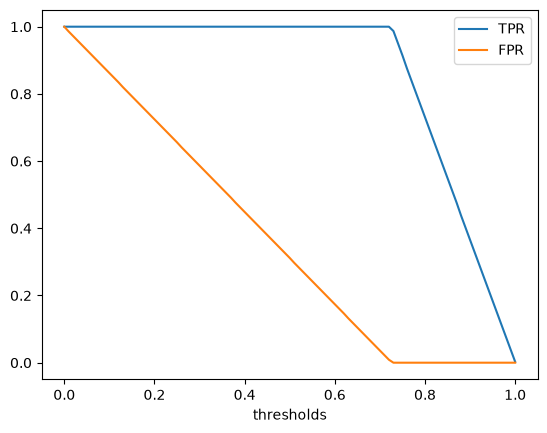

In [44]:
plt.plot(df_ideal.threshold, df_ideal.tpr, label='TPR')
plt.plot(df_ideal.threshold, df_ideal.fpr, label='FPR')
plt.xlabel("thresholds")
plt.legend()

**threshold 0.726**. accuracy **1.0** means it catches all 386 churners and flags none of the 1,023 non-churners: **TPR 100%, FPR 0%, 0 false negatives, 0 false positives**.

### Catchings and interpretation

- At low thresholds, **it catches every churner**, but also flags many non-churners. At threshold 0, it flags everyone.
- Raising the threshold reduces false alarms while TPR stays at 100%, until the separation between the two groups.
- Near **0.726**, the plot reaches the ideal operating point: **all churners caught, no non-churners flagged**.
- Above that point, FPR stays at zero, but the model starts missing churners: at 0.8 it catches 282 of 386; at 0.9 it catches 141; at 1.0 it catches just 1.

**The ideal TPR stays at 1.0 for every threshold below 0.726 - it catches all churners while they all score higher than any non-churner - and only then drops. The ideal FPR falls to 0 at that same point.**

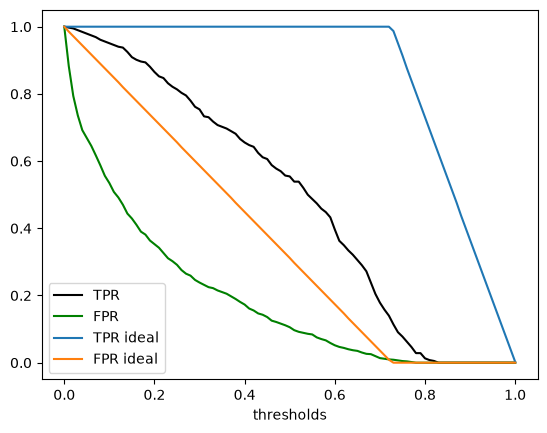

In [45]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR', color='green')

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR ideal')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR ideal')

# plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR random', color='grey')
# plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR random', color='grey')
plt.xlabel("thresholds")
plt.legend()

## model vs. ideal
The x-axis is the **decision threshold**; the y-axis shows the rate from 0 to 1. The **black** and **green** curves are the trained model’s TPR and FPR. The **blue** and **orange** curves are the ideal model’s TPR and FPR.

- **As the threshold rises, both rates generally fall.** The model predicts churn for fewer customers: it catches fewer actual churners (TPR falls), but also flags fewer non-churners (FPR falls).
- **The trained model separates the classes better than random guessing:** its black TPR curve is above its green FPR curve over most thresholds.
- At threshold **0.5**, the confusion counts give:
  - $TPR = (\frac{214}{386} \approx 55.4\%)$: it catches 214 churners and misses 172.
  - $FPR = (\frac{108}{1023} \approx 10.6\%)$: it falsely flags 108 non-churners.
- **The ideal curves** show perfect separation by construction: TPR stays at 100% while FPR drops to 0%, around the separating threshold of \(0.726\). Above that point, FPR remains zero, but TPR starts to fall as churners are missed.

**Tutor: Plotting our model together with the ideal one makes the comparison obvious: the black TPR curve of our model is clearly below the ideal, and the green FPR curve above the ideal - the gap between them is the room our model still has to improve.**
- The statement that the model’s blue FPR curve is “above the ideal” is **not what this plot shows**. For example, at threshold 0.5, the model’s FPR is about 10.6%, while the ideal curve’s FPR is about 31.2%. More importantly, comparing the models at the *same numeric threshold* is not a fair overall comparison: the ideal scores were artificially assigned, while the trained model’s scores are probabilities. The threshold values don’t have the same meaning for both.

- A fairer comparison of their ranking performance would plot **TPR against FPR** (an ROC curve) or compare AUC.

## ROC Curve

- Each point on the curve is the model operating at one threshold
- The bottom-left corner is a conservative model (flag almost nobody, bother almost nobody), the top-right corner flags everybody.

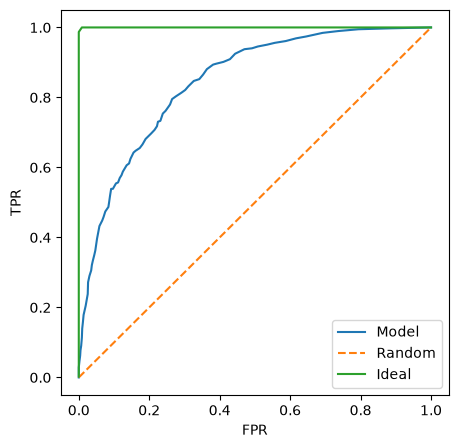

In [46]:
plt.figure(figsize=(5, 5))

plt.plot(df_scores.fpr, df_scores.tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')
plt.plot(df_ideal.fpr, df_ideal.tpr, label='Ideal')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

**The closer the curve hugs the top-left corner - high true positive rate at a low false positive rate - the better the model.**

- Random model: diagonal line from (0,0) to (1,1)
  - This means it has no discriminative power.
  - At any threshold, TPR and FPR rise together, so it cannot separate churners from non-churners.
  - AUC ≈ 0.5

- Ideal model: as close as possible to the top-left corner
  - It achieves TPR = 1 while keeping FPR = 0
  - AUC = 1
  - In practice, this is the “perfect ranking” curve

- The model: should sit between those two
  - It should be clearly above the random diagonal
  - It should be below the ideal curve
  - The closer it is to the top-left corner, the better

Conclusion from the plot:
- If your model curve is well above the random line, it is learning useful signal.
- If it is near the diagonal, it is barely better than guessing.
- If it is close to the ideal curve, it is doing excellent discrimination.
- The gap between the model and the random line tells you how much real predictive value you have beyond chance.
- The gap between the model and the ideal line tells you how much improvement is still possible.

**The best-performing model is the one with the largest area under the ROC curve and the strongest lift above the diagonal.**

For churn prediction specifically:
- You usually care about a high TPR at a low FPR
- That means the curve should bend upward quickly and stay near the top-left corner
- This is more important than raw accuracy, because accuracy can look good even when churn is rare

In [ ]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

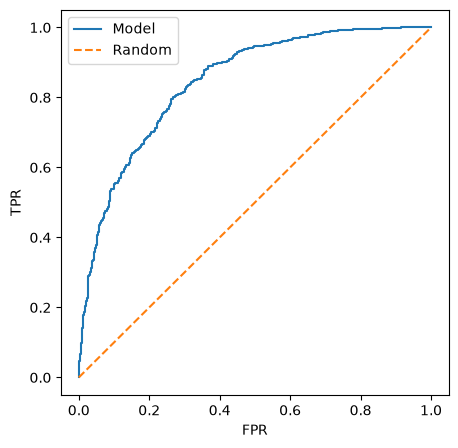

In [62]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()

### ROC AUC
- Area under the ROC curve

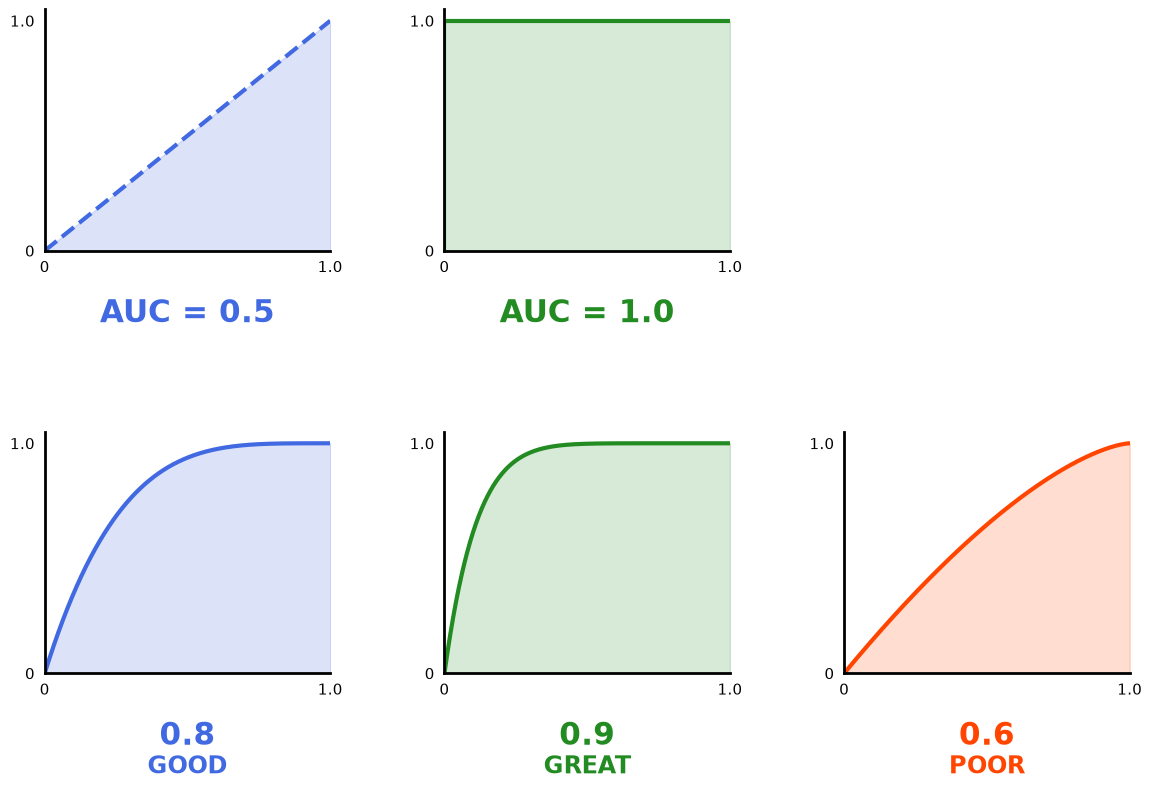

In [ ]:
x_values = np.linspace(0, 1, 500)

curves = [
    (x_values, x_values, "0.5", "RANDOM", "royalblue"),
    (np.array([0, 0, 1]), np.array([0, 1, 1]),
     "1.0", "PERFECT", "forestgreen"),
    (x_values, 1 - (1 - x_values)**4, "0.8", "GOOD", "royalblue"),
    (x_values, 1 - (1 - x_values)**9, "0.9", "GREAT", "forestgreen"),
    (x_values, 1 - (1 - x_values)**1.5, "0.6", "POOR", "orangered"),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.patch.set_facecolor("white")

positions = [(0, 0), (0, 1), (1, 0), (1, 1), (1, 2)]

for i, (x_data, y_data, auc, label, color) in enumerate(curves):
    ax = axes[positions[i]]

    ax.plot(
        x_data, y_data,
        color=color,
        linewidth=3,
        linestyle="--" if auc == "0.5" else "-"
    )

    ax.fill_between(x_data, 0, y_data, color=color, alpha=0.18)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["0", "1.0"])
    ax.set_yticklabels(["0", "1.0"])

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2)
    ax.spines["bottom"].set_linewidth(2)
    ax.tick_params(length=0, labelsize=11, pad=7)

    score_text = f"AUC = {auc}" if i < 2 else auc

    ax.text(
        0.5, -0.20, score_text,
        transform=ax.transAxes,
        ha="center", va="top",
        fontsize=22, fontweight="bold",
        color=color
    )

    if i >= 2:
        ax.text(
            0.5, -0.34, label,
            transform=ax.transAxes,
            ha="center", va="top",
            fontsize=17, fontweight="bold",
            color=color
        )

axes[0, 2].axis("off")

fig.subplots_adjust(
    hspace=0.75,
    wspace=0.4,
    bottom=0.12,
    top=0.95
)

plt.show()


- The ideal model covers the whole square above the diagonal, so its AUC is 1.
- The random model sits on the diagonal and covers only the triangle below it, so its AUC is 0.5.
- A real model lands between `0.5` and `1`: the closer its curve is to the top-left corner, the larger the area under it.

Scikit-learn `auc` works for any curve, not only ROC curves

In [66]:
auc(fpr, tpr)

0.8445038720820102

In [67]:
auc(df_scores.fpr, df_scores.tpr)

0.8443696534119398

In [68]:
auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

computes the ROC curve and the area in one step:

In [70]:
roc_auc_score(y_val, y_pred)

0.8445038720820102

> **AUC is the probability that a randomly selected positive example has a greater score than a randomly selected negative example.**

 pick a random customer who churned and a random customer who stayed - how likely is it that our model gave the churner the higher risk score? That probability is exactly the AUC.

In [75]:
y_val[9], y_val[1], y_pred[9], y_pred[1]

(np.int64(1),
 np.int64(0),
 np.float64(0.48374819536390246),
 np.float64(0.20992802695172616))

First we split the predictions into the scores of negatives and positives:

In [78]:
neg = y_pred[y_val == 0]
pos = y_pred[y_val == 1]

Then we repeatedly draw one score from each group at random and count how often the positive one wins:

In [81]:
import random

n = 100000
success = 0

for i in range(n):
    neg_ind = random.randint(0, len(neg) - 1)
    pos_ind = random.randint(0, len(pos) - 1)

    if pos[pos_ind] > neg[neg_ind]:
        success += 1

success/n

0.84547

In vectorized NumPy: draw 50000 random indices into each group **at once**, compare the scores **element-wise**, and take the mean of the resulting boolean array:

In [ ]:
n = 50000

neg_ind = np.random.randint(0, len(neg), size=n)
pos_ind = np.random.randint(0, len(pos), size=n)

(pos[pos_ind] > neg[neg_ind]).mean()

np.float64(0.844804)

AUC is a popular metric for binary classification: 
- it says how well the model separates the two classes.
- it does not depend on the class balance or on any particular threshold.